In [2]:
import platform
import numpy as np
import tensorflow as tf
import time
from tensorflow.keras import layers, Model
import matplotlib.pyplot as plt

useGPU = True   # flip to False to force CPU-only, even if a GPU is available/installed

print(f"Platform: {platform.system()} {platform.machine()}")
print(f"TensorFlow: {tf.__version__}")

if not useGPU:
    tf.config.set_visible_devices([], 'GPU')

gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs found: {gpus}")
print(f"useGPU: {useGPU}")

tf.random.set_seed(0)
np.random.seed(0)

# Memory growth: same API works for both CUDA and Metal
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

tf.debugging.set_log_device_placement(False)

Platform: Darwin arm64
TensorFlow: 2.14.0
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
useGPU: True


In [21]:
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # must be set before GPUs are initialized; ignore if already done
 
tf.debugging.set_log_device_placement(False)

## Config

In [2]:
class ToyGame:
    """Config + vectorized toy matrix game in one object. B parallel episodes."""

    # --- config (class-level defaults, override via constructor if needed) ---
    N: int = 2
    n_actions: int = 2
    n_states: int = 2
    ep_len: int = 100
    gamma: float = 0.99
    gae_lambda: float = 0.95
    p_no_adv: float = 0.5
    ppo_clip: float = 0.05
    ppo_epochs: int = 5

    def __init__(self, B, ep_len=100):
        self.B = B
        self.ep_len = ep_len
        self.reset()

    def reset(self):
        self.t = 0
        self.state = np.random.randint(self.n_states, size=self.B)   # (B,) ints
        return self._obs()

    def _obs(self):
        oh = np.zeros((self.B, self.n_states), dtype=np.float32)
        oh[np.arange(self.B), self.state] = 1.0
        return np.repeat(oh[:, None, :], self.N, axis=1)             # (B, N, n_states)

    def step(self, actions):
        """actions: (B, N) int array."""
        a = actions.astype(int)
        agree = (a[:, 0] == a[:, 1])                # (B,)
        in_s1 = (self.state == 0)

        r = np.where(in_s1, agree.astype(np.float32),
                            (~agree).astype(np.float32))

        next_state = np.where(
            in_s1,
            np.where(agree, 1, 0),
            np.where(agree, 0, 1),
        )
        self.state = next_state
        self.t += 1
        done = self.t >= self.ep_len
        return self._obs(), r.astype(np.float32), done

    def sample_types(self):
        """theta: (B, N) int, at most one adversary per row."""
        theta = np.zeros((self.B, self.N), dtype=int)
        has_adv = np.random.rand(self.B) >= self.p_no_adv
        adv_idx = np.random.randint(self.N, size=self.B)
        theta[has_adv, adv_idx[has_adv]] = 1
        return theta

# sanity check
game = ToyGame(B=4)
obs = game.reset()
print("obs shape:", obs.shape, "| initial states:", game.state)

obs2, r, done = game.step(np.array([[0,0],[0,1],[1,0],[1,1]]))
print("states after step:", game.state, "| rewards:", r)

theta = game.sample_types()
print("theta:\n", theta)

obs shape: (4, 2, 2) | initial states: [1 1 1 1]
states after step: [0 1 1 0] | rewards: [0. 1. 1. 0.]
theta:
 [[0 0]
 [1 0]
 [0 0]
 [0 1]]


In [3]:
HIDDEN = 128
def build_policy(game, hidden=HIDDEN):
    """Cooperative policy (shared across agents).
       Input: [obs one-hot | belief probs (N+1,)] -> action logits."""
    id_in = layers.Input(shape=(game.N,), name="agent_id")
    obs_in = layers.Input(shape=(game.n_states,), name="obs")
    belief_in = layers.Input(shape=(game.N + 1,), name="belief")   # N+1: nobody + each agent
    x = layers.Concatenate()([obs_in,id_in, belief_in])
    x = layers.Dense(hidden, activation="relu")(x)
    x = layers.Dense(hidden, activation="relu")(x)
    logits = layers.Dense(game.n_actions, name="action_logits")(x)
    return Model([obs_in, id_in, belief_in], logits, name="policy")

def build_adversary(game, hidden=HIDDEN):
    """Adversary policy. Input: own obs -> action logits."""
    obs_in = layers.Input(shape=(game.n_states,), name="obs")
    x = layers.Dense(hidden, activation="relu")(obs_in)
    x = layers.Dense(hidden, activation="relu")(x)
    logits = layers.Dense(game.n_actions, name="adv_logits")(x)
    return Model(obs_in, logits, name="adversary")

def build_critic(game, hidden=HIDDEN):
    """Centralized critic (training only).
       Input: [global state | belief probs] -> scalar value."""
    state_in = layers.Input(shape=(game.n_states,), name="state")
    belief_in = layers.Input(shape=(game.N + 1,), name="belief")
    x = layers.Concatenate()([state_in, belief_in])
    x = layers.Dense(hidden, activation="relu")(x)
    x = layers.Dense(hidden, activation="relu")(x)
    value = layers.Dense(1, name="value")(x)
    return Model([state_in, belief_in], value, name="critic")

def build_belief(game, feat_dim, hidden=HIDDEN):
    """Categorical belief (GRU): P(nobody | agent i is adversary), softmax over N+1.
       Input: sequence of feature vectors (T, feat_dim).
       Output: sequence of belief distributions (T, N+1)."""
    feat_in = layers.Input(shape=(None, feat_dim), name="belief_feats")
    h = layers.GRU(hidden, return_sequences=True)(feat_in)
    b = layers.Dense(game.N + 1, activation="softmax", name="belief_out")(h)
    return Model(feat_in, b, name="belief")

print("network builders defined")

network builders defined


In [4]:
def belief_input(state_oh, prev_actions, game):
    """state_oh: (B, n_states), prev_actions: (B, N) ints -> (B, feat_dim)
       feat = [state one-hot | all agents' previous actions one-hot]"""
    B = state_oh.shape[0]
    a_oh = np.eye(game.n_actions, dtype=np.float32)[prev_actions].reshape(B, -1)  # (B, N*A)
    return np.concatenate([state_oh, a_oh], axis=1).astype(np.float32)

FEAT_DIM = ToyGame(B=1).n_states + ToyGame(B=1).N * ToyGame(B=1).n_actions
print("belief input dim:", FEAT_DIM)

belief input dim: 6


In [5]:
game = ToyGame(B=100)   # temporary, just to build networks with correct shapes

policy    = build_policy(game)
adversary = build_adversary(game)
critic    = build_critic(game)
belief    = build_belief(game, FEAT_DIM)

lr_policy, lr_adv, lr_critic, lr_belief = 5e-5, 5e-5, 5e-5, 5e-5

opt_policy = tf.keras.optimizers.legacy.Adam(lr_policy)
opt_adv    = tf.keras.optimizers.legacy.Adam(lr_adv)
opt_critic = tf.keras.optimizers.legacy.Adam(lr_critic)
opt_belief = tf.keras.optimizers.legacy.Adam(lr_belief)

# shape check
dummy_obs = tf.zeros((1, game.n_states))
dummy_bel = tf.zeros((1, game.N + 1))
dummy_seq = tf.zeros((1, 5, FEAT_DIM))
dummy_id = tf.zeros((1, game.N))
print("policy   :", policy([dummy_obs, dummy_id, dummy_bel]).shape)     # (1, n_actions)
print("adversary:", adversary(dummy_obs).shape)                # (1, n_actions)
print("critic   :", critic([dummy_obs, dummy_bel]).shape)      # (1, 1)
print("belief   :", belief(dummy_seq).shape)                   # (1, 5, N+1)

policy   : (1, 2)
adversary: (1, 2)
critic   : (1, 1)
belief   : (1, 5, 3)


## Rollouts

In [6]:
def make_belief_step(belief_model):
    """Bind a belief_step function to a SPECIFIC belief network, not the current global one."""
    gru  = belief_model.get_layer(index=1)
    head = belief_model.get_layer("belief_out")
    cell = gru.cell
    @tf.function(reduce_retracing=True)
    def step(feat_t, h_prev):
        out, new_states = cell(feat_t, states=[h_prev])
        b = head(out)
        return b, new_states[0]
    return step

def choose_action(logits_np):
    """Sample an action from logits. logits_np:(M,n_actions) -> actions:(M,)"""
    m = logits_np - logits_np.max(axis=1, keepdims=True)
    probs = np.exp(m); probs /= probs.sum(axis=1, keepdims=True)
    r = np.random.rand(probs.shape[0], 1)
    return (probs.cumsum(axis=1) > r).argmax(axis=1).astype(int)

# smoke test
_h = tf.zeros((4, HIDDEN))
_f = tf.zeros((4, FEAT_DIM))
belief_step = make_belief_step(belief)
_b, _h2 = belief_step(_f, _h)
print("belief_step ok | b:", _b.shape, "| h:", _h2.shape)

belief_step ok | b: (4, 3) | h: (4, 128)


In [7]:
def run_episodes(game, hidden=HIDDEN):
    """Run B episodes. Returns dict of (B, T, ...) arrays."""
    game.reset()
    theta = game.sample_types() # (B, N)
    
    prev_actions = np.zeros((game.B, game.N), dtype=int)
    h = tf.zeros((game.B, hidden))
    S_state, S_belief, S_actions, S_reward, S_feat = [], [], [], [], []
    S_old_logp_coop, S_old_logp_adv = [], []

    for t in range(game.ep_len):
        obs_all = game._obs()         # (B, N, n_states)
        state_oh = obs_all[:, 0, :]   # (B, n_states)

        # Belief
        b_in = belief_input(state_oh, prev_actions, game) # Format beliefNN input (B, n_states + N * n_actions)
        b_tf, h = belief_step(tf.constant(b_in), h)
        b_t = b_tf.numpy()                                # belief (B, N+1)
        
        # PolicyNN
        state_rep = obs_all.reshape(-1, game.n_states)                                             # (B*N, n_states)
        id_rep = np.tile(np.eye(game.N, dtype=np.float32), (game.B, 1))                            # (B*N, N)
        belief_rep = np.repeat(b_t, game.N, axis=0)                                                # (B*N, N+1)
        c_logits = policy([state_rep, id_rep, belief_rep]).numpy()                                         # (B*N, n_actions)   call policyNN
        a_coop = choose_action(c_logits).reshape(game.B, game.N)                                   # (B, N)             choose action randomly from logits using softmax
        logp_all = tf.nn.log_softmax(c_logits, axis=-1)                                            # (B*N, n_actions)   computes log-probability: log(p_i) = log(e^x/\sum e^x) = log(e^x) - log(\sum e^x)
        old_lp_coop = tf.reshape(    
            tf.gather(logp_all, a_coop.reshape(-1), batch_dims=1), (game.B,game.N)                 # (B, N)             get the log-probability of the action chosen
        )

        # AdversaryNN
        a_logits = adversary(state_rep).numpy()                                                    # (B*N, n_actions)   call adversaryNN
        a_adv = choose_action(a_logits).reshape(game.B, game.N)                                    # (B, N)             choose action randomly from logits softmax
        logp_adv = tf.nn.log_softmax(a_logits, axis=-1)                                            # (B*N, n_actions)   computes log-probs
        old_lp_adv = tf.reshape(
            tf.gather(logp_adv, a_adv.reshape(-1), batch_dims=1), (game.B,game.N)                  # (B, N)             get the log-probability of the action chosen
        )

        actions = np.where(theta == 1, a_adv, a_coop)                                              # change actions for adversaries
        _, r, done = game.step(actions)

        S_state.append(state_oh); S_belief.append(b_t)
        S_actions.append(actions.copy()); S_reward.append(r); S_feat.append(b_in)
        S_old_logp_coop.append(old_lp_coop.numpy()); S_old_logp_adv.append(old_lp_adv.numpy())
        prev_actions = actions
        if done: break

    stack = lambda L: np.stack(L, axis=1)
    return dict(
        state=stack(S_state), belief=stack(S_belief),
        actions=stack(S_actions), reward=stack(S_reward), feat=stack(S_feat),
        old_logp_coop=stack(S_old_logp_coop), old_logp_adv=stack(S_old_logp_adv),
        theta=np.repeat(theta[:, None, :], len(S_reward), axis=1),
    )

game = ToyGame(B=2)
traj = run_episodes(game)
print("Output of run episodes")
for k, v in traj.items():
    print(f"{k:15s} shape {v.shape}")

Output of run episodes
state           shape (2, 100, 2)
belief          shape (2, 100, 3)
actions         shape (2, 100, 2)
reward          shape (2, 100)
feat            shape (2, 100, 6)
old_logp_coop   shape (2, 100, 2)
old_logp_adv    shape (2, 100, 2)
theta           shape (2, 100, 2)


## Loss Functions

In [8]:
def compute_gae(traj, game):
    """Returns G (returns-to-go) and adv (GAE advantages), each (B, T)."""
    B, T = traj['reward'].shape
    rewards = traj['reward']

    state_flat  = traj['state'].reshape(B*T, game.n_states)
    belief_flat = traj['belief'].reshape(B*T, game.N + 1)
    V = critic([state_flat, belief_flat]).numpy().reshape(B, T)
    
    adv = np.zeros((B, T), dtype=np.float32)
    
    last_gae = np.zeros(B, dtype=np.float32)
    for t in reversed(range(T)):
        V_next = V[:, t+1] if t+1 < T else np.zeros(B, dtype=np.float32)
        delta = rewards[:, t] + game.gamma * V_next - V[:, t]
        last_gae = delta + game.gamma * game.gae_lambda * last_gae        
        adv[:, t] = last_gae
    G = adv + V     # (B,T)

    adv_norm = (adv - adv.mean()) / (adv.std() + 1e-8)
    return G.astype(np.float32), adv_norm.astype(np.float32)

# smoke test
G, adv = compute_gae(traj, game)
print("G shape:", G.shape, "| adv shape:", adv.shape)

G shape: (2, 100) | adv shape: (2, 100)


In [9]:
def make_critic_step():
    @tf.function(reduce_retracing=True)
    def step(state, belief_in, target, critic, opt):
        with tf.GradientTape() as tape:
            V = critic([state, belief_in])
            loss = tf.reduce_mean((target - V) ** 2)
        grads = tape.gradient(loss, critic.trainable_variables)
        opt.apply_gradients(zip(grads, critic.trainable_variables))
        return loss
    return step

def update_critic(traj, G, game, step_fn):
    B, T = G.shape
    state  = traj['state'].reshape(B*T, game.n_states).astype(np.float32)
    belief_in = traj['belief'].reshape(B*T, game.N + 1).astype(np.float32)
    target = G.reshape(B*T, 1).astype(np.float32)
    loss = step_fn(tf.constant(state), tf.constant(belief_in), tf.constant(target), critic, opt_critic)
    return float(loss)

print("critic loss:", update_critic(traj, G, game, make_critic_step()))

critic loss: 52.65513610839844


In [10]:
def theta_to_onehot(theta, game):
    """theta:(B,T,N) -> onehot (B,T,N+1). Index 0 = no adversary, i+1 = agent i."""
    B, T, N = theta.shape
    label_idx = np.zeros((B, T), dtype=int)
    has_adv = theta.sum(axis=2) > 0
    adv_agent = theta.argmax(axis=2)
    label_idx[has_adv] = adv_agent[has_adv] + 1
    return np.eye(N + 1, dtype=np.float32)[label_idx]

def make_belief_train_step():
    @tf.function(reduce_retracing=True)
    def step(feats_seq, labels, belief, opt):
        with tf.GradientTape() as tape:
            b_pred = belief(feats_seq)
            loss = tf.reduce_mean(tf.keras.losses.categorical_crossentropy(labels, b_pred))
        grads = tape.gradient(loss, belief.trainable_variables)
        opt.apply_gradients(zip(grads, belief.trainable_variables))
        return loss
    return step

def update_belief(traj, game, step_fn):
    labels = theta_to_onehot(traj['theta'], game)
    loss = step_fn(tf.constant(traj['feat']), tf.constant(labels), belief, opt_belief)
    return float(loss)

print("belief loss:", update_belief(traj, game, make_belief_train_step()))

print("belief loss:", update_belief(traj, game, make_belief_train_step()))

belief loss: 1.0123168230056763
belief loss: 1.0067939758300781


In [11]:
def make_policy_step():
    @tf.function(reduce_retracing=True)
    def step(state_rep, id_rep, belief_rep, actions_flat, old_logp, weight, mask, norm,
             policy, opt, clip, entropy_coef=0.01):
        with tf.GradientTape() as tape:
            logits = policy([state_rep, id_rep, belief_rep])
            logp = tf.nn.log_softmax(logits, axis=-1)
            probs = tf.nn.softmax(logits, axis=-1)
            entropy = -tf.reduce_sum(probs * logp, axis=-1)
            new_logp = tf.gather(logp, actions_flat, batch_dims=1)
            ratio = tf.exp(new_logp - old_logp)
            unclipped = ratio * weight
            clipped   = tf.clip_by_value(ratio, 1.0 - clip, 1.0 + clip) * weight
            policy_loss = -tf.reduce_sum(tf.minimum(unclipped, clipped)) / norm
            entropy_bonus = tf.reduce_sum(entropy * mask) / norm
            loss = policy_loss - entropy_coef * entropy_bonus
        grads = tape.gradient(loss, policy.trainable_variables)
        opt.apply_gradients(zip(grads, policy.trainable_variables))
        return loss
    return step

def update_policy(traj, adv, game, step_fn):
    B, T = adv.shape
    state      = traj['state'].reshape(B*T, game.n_states)
    belief_in  = traj['belief']
    belief_rep = np.repeat(belief_in[:, :, None, :], game.N, axis=2)         # (B, T, N, N+1) -- no roll
    belief_rep = belief_rep.reshape(-1, game.N + 1).astype(np.float32)
    id_rep = np.tile(np.eye(game.N, dtype=np.float32), (B*T, 1)).astype(np.float32)   # (B*T*N, N)
    # b_rolled = np.stack([np.roll(belief_in, -i, axis=2) for i in range(game.N)], axis=2)  # (B, T, N, N+1)
    actions    = traj['actions'].reshape(B*T, game.N)
    theta      = traj['theta'].reshape(B*T, game.N)
    old_logp   = traj['old_logp_coop'].reshape(B*T, game.N)
    adv_flat   = adv.reshape(B*T)
    coop_mask  = (1 - theta).astype(np.float32)

    state_rep    = np.repeat(state, game.N, axis=0).astype(np.float32)
    # belief_rep   = b_rolled.reshape(-1, game.N + 1).astype(np.float32)
    actions_flat = actions.reshape(-1).astype(np.int32)
    old_logp_flat = old_logp.reshape(-1).astype(np.float32)
    weight = (coop_mask * adv_flat[:, None]).reshape(-1).astype(np.float32)
    norm = np.float32(np.sum(coop_mask) + 1e-8)

    mask_flat = coop_mask.reshape(-1).astype(np.float32)
    loss = step_fn(tf.constant(state_rep), tf.constant(id_rep), tf.constant(belief_rep),
                    tf.constant(actions_flat), tf.constant(old_logp_flat),
                    tf.constant(weight), tf.constant(mask_flat), tf.constant(norm),
                    policy, opt_policy, game.ppo_clip)
    return float(loss)

print("policy loss:", update_policy(traj, adv, game, make_policy_step()))

policy loss: -0.006913985125720501


In [12]:
def make_adversary_train_step():
    @tf.function(reduce_retracing=True)
    def step(state_rep, actions_flat, old_logp, weight, mask, norm, adversary, opt, clip, entropy_coef=0.01):
        with tf.GradientTape() as tape:
            logits = adversary(state_rep)
            logp = tf.nn.log_softmax(logits, axis=-1)
            probs = tf.nn.softmax(logits, axis=-1)
            entropy = -tf.reduce_sum(probs * logp, axis=-1)
            new_logp = tf.gather(logp, actions_flat, batch_dims=1)
            ratio = tf.exp(new_logp - old_logp)
            unclipped = ratio * weight
            clipped   = tf.clip_by_value(ratio, 1.0 - clip, 1.0 + clip) * weight
            adv_loss = tf.reduce_sum(tf.maximum(unclipped, clipped)) / norm
            entropy_bonus = tf.reduce_sum(entropy * mask) / norm
            loss = adv_loss - entropy_coef * entropy_bonus
        grads = tape.gradient(loss, adversary.trainable_variables)
        opt.apply_gradients(zip(grads, adversary.trainable_variables))
        return loss
    return step

def update_adversary(traj, adv, game, step_fn):
    B, T = adv.shape
    state    = traj['state'].reshape(B*T, game.n_states)
    actions  = traj['actions'].reshape(B*T, game.N)
    theta    = traj['theta'].reshape(B*T, game.N).astype(np.float32)
    old_logp = traj['old_logp_adv'].reshape(B*T, game.N)
    adv_flat = adv.reshape(B*T)

    state_rep    = np.repeat(state, game.N, axis=0).astype(np.float32)
    actions_flat = actions.reshape(-1).astype(np.int32)
    old_logp_flat = old_logp.reshape(-1).astype(np.float32)
    weight = (theta * adv_flat[:, None]).reshape(-1).astype(np.float32)
    norm = np.float32(np.sum(theta) + 1e-8)

    loss = step_fn(tf.constant(state_rep), tf.constant(actions_flat), tf.constant(old_logp_flat),
                    tf.constant(weight), tf.constant(theta.reshape(-1).astype(np.float32)),
                    tf.constant(norm), adversary, opt_adv, game.ppo_clip)
    return float(loss)

print("adversary loss:", update_adversary(traj, adv, game, make_adversary_train_step()))

adversary loss: -0.006912283133715391


## Training

In [13]:
def train(B=100, n_iters=10000, interval=10, log_every=500, seed=0):
    global policy, adversary, critic, belief, belief_step
    global opt_policy, opt_adv, opt_critic, opt_belief

    tf.random.set_seed(seed); np.random.seed(seed)

    game = ToyGame(B)
    policy    = build_policy(game)
    adversary = build_adversary(game)
    critic    = build_critic(game)
    belief    = build_belief(game, FEAT_DIM)
    belief_step = make_belief_step(belief)

    opt_policy = tf.keras.optimizers.legacy.Adam(lr_policy)
    opt_adv    = tf.keras.optimizers.legacy.Adam(lr_adv)
    opt_critic = tf.keras.optimizers.legacy.Adam(lr_critic)
    opt_belief = tf.keras.optimizers.legacy.Adam(lr_belief)

    critic_step, belief_train_step = make_critic_step(), make_belief_train_step()
    policy_step, adv_step = make_policy_step(), make_adversary_train_step()

    hist = {"timesteps": [], "reward_adv": [], "reward_clean": [], "belief_acc": []}
    t0 = time.time()

    for it in range(1, n_iters + 1):
        traj = run_episodes(game)
        G, adv = compute_gae(traj, game)

        if it % interval == 0:
            for _ in range(game.ppo_epochs):
                update_critic(traj, G, game, critic_step)
            for _ in range(game.ppo_epochs):
                update_belief(traj, game, belief_train_step)
            for _ in range(game.ppo_epochs):
                update_policy(traj, adv, game, policy_step)

        for _ in range(game.ppo_epochs):
            update_adversary(traj, adv, game, adv_step)

        if it % log_every == 0:
            ep_reward = traj['reward'].mean(axis=1)
            has_adv = traj['theta'][:, 0, :].sum(axis=1) > 0
            ra = ep_reward[has_adv].mean()  if has_adv.any()   else float('nan')
            rc = ep_reward[~has_adv].mean() if (~has_adv).any() else float('nan')
            pred_label = traj['belief'].argmax(axis=2)
            true_label = theta_to_onehot(traj['theta'], game).argmax(axis=2)
            acc = (pred_label == true_label).mean()
            hist["timesteps"].append(it)
            hist["reward_adv"].append(ra)
            hist["reward_clean"].append(rc)
            hist["belief_acc"].append(acc)
            print(f"iter {it:5d} | reward(adv) {ra:.3f} | reward(clean) {rc:.3f} "
                  f"| belief acc {acc:.3f} | {time.time()-t0:.0f}s")

    return hist

In [14]:
# after training, check what the policy actually does in each state
for state_idx in [0, 1]:
    s = np.zeros((1, game.n_states), dtype=np.float32); s[0, state_idx] = 1.0
    b = np.zeros((1, game.N+1), dtype=np.float32); b[0, 0] = 1.0   # "nobody" belief
    for agent_id in range(game.N):
        idv = np.zeros((1, game.N), dtype=np.float32); idv[0, agent_id] = 1.0
        logits = policy([s, idv, b]).numpy()
        probs = np.exp(logits) / np.exp(logits).sum()
        print(f"state s{state_idx+1}, agent {agent_id}: action probs = {probs.round(3)}")

for state_idx in [0, 1]:
    s = np.zeros((1, game.n_states), dtype=np.float32); s[0, state_idx] = 1.0
    b = np.zeros((1, game.N+1), dtype=np.float32); b[0, 1] = 1.0   # "nobody" belief
    for agent_id in range(game.N):
        idv = np.zeros((1, game.N), dtype=np.float32); idv[0, agent_id] = 1.0
        logits = policy([s, idv, b]).numpy()
        probs = np.exp(logits) / np.exp(logits).sum()
        print(f"state s{state_idx+1}, agent {agent_id}: action probs = {probs.round(3)}")

state s1, agent 0: action probs = [[0.496 0.504]]
state s1, agent 1: action probs = [[0.535 0.465]]
state s2, agent 0: action probs = [[0.471 0.529]]
state s2, agent 1: action probs = [[0.529 0.471]]
state s1, agent 0: action probs = [[0.473 0.527]]
state s1, agent 1: action probs = [[0.498 0.502]]
state s2, agent 0: action probs = [[0.481 0.519]]
state s2, agent 1: action probs = [[0.507 0.493]]


In [15]:
N_SEEDS = 5
all_hists = []
all_teams = []
for seed in range(N_SEEDS):
    print(f"\n=== SEED {seed} ===")
    h = train(B=100, n_iters=10000, interval=10, log_every=100, seed=seed)
    all_hists.append(h)
    all_teams.append({"policy": policy, "critic": critic, "belief": belief})


=== SEED 0 ===
iter   100 | reward(adv) 0.501 | reward(clean) 0.497 | belief acc 0.390 | 27s
iter   200 | reward(adv) 0.500 | reward(clean) 0.499 | belief acc 0.560 | 54s
iter   300 | reward(adv) 0.493 | reward(clean) 0.503 | belief acc 0.460 | 81s
iter   400 | reward(adv) 0.505 | reward(clean) 0.510 | belief acc 0.400 | 108s
iter   500 | reward(adv) 0.477 | reward(clean) 0.504 | belief acc 0.380 | 135s
iter   600 | reward(adv) 0.507 | reward(clean) 0.488 | belief acc 0.440 | 161s
iter   700 | reward(adv) 0.507 | reward(clean) 0.503 | belief acc 0.500 | 188s
iter   800 | reward(adv) 0.477 | reward(clean) 0.510 | belief acc 0.430 | 215s
iter   900 | reward(adv) 0.460 | reward(clean) 0.506 | belief acc 0.580 | 242s
iter  1000 | reward(adv) 0.489 | reward(clean) 0.494 | belief acc 0.530 | 269s
iter  1100 | reward(adv) 0.528 | reward(clean) 0.511 | belief acc 0.530 | 296s
iter  1200 | reward(adv) 0.486 | reward(clean) 0.536 | belief acc 0.440 | 323s
iter  1300 | reward(adv) 0.417 | reward

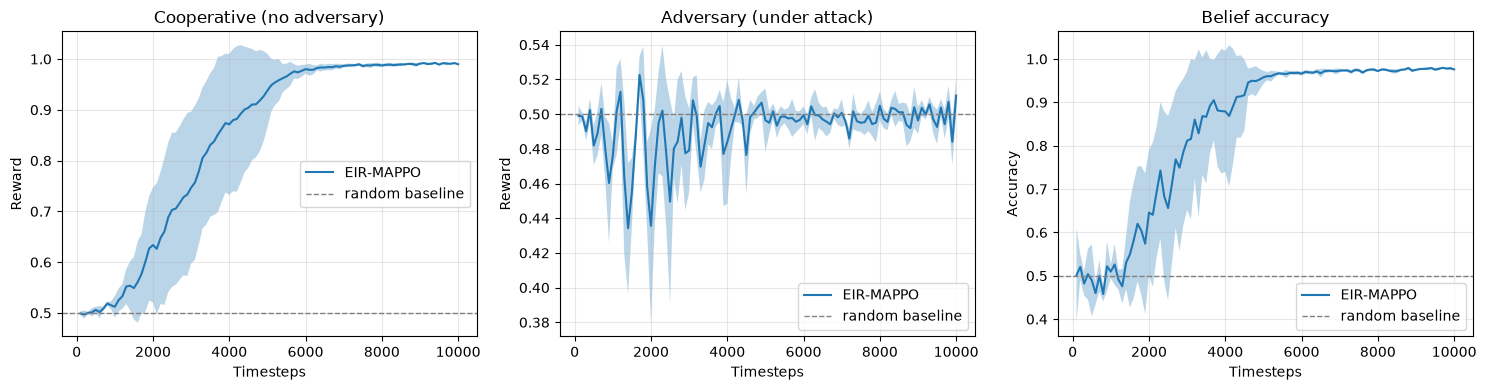

In [16]:
def mean_ci(x_data):
    m = x_data.mean(axis=0)
    se = x_data.std(axis=0) / np.sqrt(x_data.shape[0])
    ci = 1.96 * se
    return m, ci
        
def plot_paper_style(all_hists):
    clean = np.array([h["reward_clean"] for h in all_hists])   # (n_seeds, n_points)
    adv   = np.array([h["reward_adv"]   for h in all_hists])
    acc   = np.array([h["belief_acc"]   for h in all_hists])
    x     = np.array(all_hists[0]["timesteps"]) 
        
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, data, title in zip(axes, [clean, adv, acc],
                              ["Cooperative (no adversary)", "Adversary (under attack)",
                               "Belief accuracy"]):
        m, ci = mean_ci(data)
        # x = np.arange(len(m))
        ax.plot(x, m, label="EIR-MAPPO")
        ax.fill_between(x, m - ci, m + ci, alpha=0.3)
        ax.set_xlabel("Timesteps")
        ax.set_ylabel("Reward" if "Belief" not in title else "Accuracy")
        ax.set_title(title)
        ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='random baseline')
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
plot_paper_style(all_hists)

In [17]:
for state_idx in [0, 1]:
    s = np.zeros((1, game.n_states), dtype=np.float32); s[0, state_idx] = 1.0
    b = np.zeros((1, game.N+1), dtype=np.float32); b[0, 0] = 1.0   # "nobody" belief
    for agent_id in range(game.N):
        idv = np.zeros((1, game.N), dtype=np.float32); idv[0, agent_id] = 1.0
        logits = policy([s, idv, b]).numpy()
        probs = np.exp(logits) / np.exp(logits).sum()
        print(f"state s{state_idx+1}, agent {agent_id}: action probs = {probs.round(3)}")

state s1, agent 0: action probs = [[0.089 0.911]]
state s1, agent 1: action probs = [[0.282 0.718]]
state s2, agent 0: action probs = [[0.001 0.999]]
state s2, agent 1: action probs = [[0.999 0.001]]


## Evaluation

In [18]:
def run_frozen_eval_episodes(game, atk_adversary, team_policy, team_belief_step, target_agent, hidden=HIDDEN):
    game.reset()
    theta = np.zeros((game.B, game.N), dtype=int)
    theta[:, target_agent] = 1                      # force THIS agent as the sole adversary, every episode

    prev_actions = np.zeros((game.B, game.N), dtype=int)
    h = tf.zeros((game.B, hidden))
    S_state, S_belief, S_actions, S_reward, S_feat, S_old_logp_adv = [], [], [], [], [], []
    for t in range(game.ep_len):
        obs_all = game._obs()
        state_oh = obs_all[:, 0, :]
        b_in = belief_input(state_oh, prev_actions, game)
        b_tf, h = team_belief_step(tf.constant(b_in), h)      # this team's belief, not the global one
        b_t = b_tf.numpy()
        state_rep = obs_all.reshape(-1, game.n_states)
        id_rep = np.tile(np.eye(game.N, dtype=np.float32), (game.B, 1))
        belief_rep = np.repeat(b_t, game.N, axis=0)
        c_logits = team_policy([state_rep, id_rep, belief_rep]).numpy()   # this team's policy
        a_coop = choose_action(c_logits).reshape(game.B, game.N)
        a_logits = atk_adversary(state_rep).numpy()
        a_adv = choose_action(a_logits).reshape(game.B, game.N)
        logp_adv = tf.nn.log_softmax(a_logits, axis=-1)
        old_lp_adv = tf.reshape(tf.gather(logp_adv, a_adv.reshape(-1), batch_dims=1), (game.B, game.N))
        actions = np.where(theta == 1, a_adv, a_coop)
        _, r, done = game.step(actions)
        S_state.append(state_oh); S_belief.append(b_t)
        S_actions.append(actions.copy()); S_reward.append(r); S_feat.append(b_in)
        S_old_logp_adv.append(old_lp_adv.numpy())
        prev_actions = actions
        if done: break
    stack = lambda L: np.stack(L, axis=1)
    return dict(state=stack(S_state), belief=stack(S_belief), actions=stack(S_actions),
                reward=stack(S_reward), feat=stack(S_feat), old_logp_adv=stack(S_old_logp_adv),
                theta=np.repeat(theta[:, None, :], len(S_reward), axis=1))

def compute_gae_frozen(traj, game, team_critic):
    B, T = traj['reward'].shape
    rewards = traj['reward']
    state_flat  = traj['state'].reshape(B*T, game.n_states)
    belief_flat = traj['belief'].reshape(B*T, game.N + 1)
    V = team_critic([state_flat, belief_flat]).numpy().reshape(B, T)   # this team's critic
    adv = np.zeros((B, T), dtype=np.float32); last_gae = np.zeros(B, dtype=np.float32)
    for t in reversed(range(T)):
        V_next = V[:, t+1] if t+1 < T else np.zeros(B, dtype=np.float32)
        delta = rewards[:, t] + game.gamma * V_next - V[:, t]
        last_gae = delta + game.gamma * game.gae_lambda * last_gae
        adv[:, t] = last_gae
    G = adv + V
    return G.astype(np.float32), ((adv - adv.mean()) / (adv.std() + 1e-8)).astype(np.float32)

def make_adversary_step():
    @tf.function(reduce_retracing=True)
    def step(state_rep, actions_flat, old_logp, weight, mask, norm, adversary, opt, clip, entropy_coef=0.01):
        with tf.GradientTape() as tape:
            logits = adversary(state_rep)
            logp = tf.nn.log_softmax(logits, axis=-1)
            probs = tf.nn.softmax(logits, axis=-1)
            entropy = -tf.reduce_sum(probs * logp, axis=-1)
            new_logp = tf.gather(logp, actions_flat, batch_dims=1)
            ratio = tf.exp(new_logp - old_logp)
            unclipped = ratio * weight
            clipped   = tf.clip_by_value(ratio, 1.0 - clip, 1.0 + clip) * weight
            adv_loss = tf.reduce_sum(tf.maximum(unclipped, clipped)) / norm
            entropy_bonus = tf.reduce_sum(entropy * mask) / norm
            loss = adv_loss - entropy_coef * entropy_bonus
        grads = tape.gradient(loss, adversary.trainable_variables)
        opt.apply_gradients(zip(grads, adversary.trainable_variables))
        return loss
    return step

def update_adversary_frozen(traj, adv, game, net, opt, step_fn):
    B, T = adv.shape
    state = traj['state'].reshape(B*T, game.n_states)
    actions = traj['actions'].reshape(B*T, game.N)
    theta = traj['theta'].reshape(B*T, game.N).astype(np.float32)
    old_logp = traj['old_logp_adv'].reshape(B*T, game.N)
    adv_flat = adv.reshape(B*T)
    state_rep = np.repeat(state, game.N, axis=0).astype(np.float32)
    actions_flat = actions.reshape(-1).astype(np.int32)
    old_logp_flat = old_logp.reshape(-1).astype(np.float32)
    weight = (theta * adv_flat[:, None]).reshape(-1).astype(np.float32)
    norm = np.float32(np.sum(theta) + 1e-8)
    loss = step_fn(tf.constant(state_rep), tf.constant(actions_flat), tf.constant(old_logp_flat),
                   tf.constant(weight), tf.constant(theta.reshape(-1).astype(np.float32)),
                   tf.constant(norm), net, opt, game.ppo_clip)
    return float(loss)

def train_fresh_adversary(team, target_agent, B=100, n_iters=10000, log_every=100, seed=123):
    tf.random.set_seed(seed); np.random.seed(seed)
    team_policy, team_critic = team["policy"], team["critic"]
    team_belief_step = make_belief_step(team["belief"])
    fresh_adversary = build_adversary(game)
    opt_fresh_adv = tf.keras.optimizers.legacy.Adam(lr_adv)
    step_fn = make_adversary_step()
    eval_game = ToyGame(B)
    hist = {"reward_adv": [], "belief_acc": []}
    for it in range(1, n_iters + 1):
        traj = run_frozen_eval_episodes(eval_game, fresh_adversary, team_policy, team_belief_step, target_agent)
        G, adv = compute_gae_frozen(traj, eval_game, team_critic)
        for _ in range(eval_game.ppo_epochs):
            update_adversary_frozen(traj, adv, eval_game, fresh_adversary, opt_fresh_adv, step_fn)
        if it % log_every == 0:
            ra = traj['reward'].mean(axis=1).mean()
            hist["reward_adv"].append(ra)
    return hist, fresh_adversary

In [ ]:
attack_hists = []
for seed_idx, team in enumerate(all_teams):
    for target_agent in range(game.N):
        print(f"=== attacking seed {seed_idx}, agent {target_agent} ===")
        h, _ = train_fresh_adversary(team, target_agent, seed=1000*seed_idx + target_agent)
        attack_hists.append(h)
        print(f"    final reward(adv) = {h['reward_adv'][-1]:.3f}")

=== attacking seed 0, agent 0 ===
    final reward(adv) = 0.361
=== attacking seed 0, agent 1 ===
    final reward(adv) = 0.290
=== attacking seed 1, agent 0 ===
    final reward(adv) = 0.316
=== attacking seed 1, agent 1 ===
    final reward(adv) = 0.375
=== attacking seed 2, agent 0 ===


In [ ]:
finals = np.array([h["reward_adv"][-1] for h in attack_hists])
print(f"Honest robustness (5 seeds x {game.N} agents = {len(finals)} attacks): "
      f"{finals.mean():.3f} +/- {1.96*finals.std()/np.sqrt(len(finals)):.3f}")

In [ ]:
def plot_all_attacks(hists, log_every=100):
    x = np.arange(1, len(hists[0]["reward_adv"]) + 1) * log_every
    plt.figure(figsize=(7, 4))
    for i, h in enumerate(hists):
        seed_idx, target_agent = divmod(i, game.N)
        plt.plot(x, h["reward_adv"], alpha=0.6, label=f"seed {seed_idx}, agent {target_agent}")
    plt.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='random baseline')
    plt.xlabel("adversary training iteration")
    plt.ylabel("reward under attack")
    plt.title("Honest eval: all 10 individual attack runs")
    plt.legend(fontsize=8, ncol=2)
    plt.grid(alpha=0.3)
    plt.show()

plot_all_attacks(attack_hists)

In [ ]:
def plot_reward_under_attack_avg(hists, log_every=100):
    data = np.array([h["reward_adv"] for h in hists])   # (10, n_points)
    m = data.mean(axis=0)
    ci = 1.96 * data.std(axis=0) / np.sqrt(data.shape[0])
    x = np.arange(1, len(m) + 1) * log_every

    plt.figure(figsize=(6, 4))
    plt.plot(x, m, color='red', label="reward under attack (mean over 5 seeds x 2 agents)")
    plt.fill_between(x, m - ci, m + ci, color='red', alpha=0.3)
    plt.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='random baseline')
    plt.xlabel("adversary training iteration")
    plt.ylabel("reward under attack")
    plt.title("Honest eval: reward under attack (5 seeds x N agents)")
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

plot_reward_under_attack_avg(attack_hists)